In [11]:
# ---- sagle imports ek jagi ----
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split   # split karnyasaathi


df = pd.read_csv("../data/processed/ckd_clean.csv")

# X = input columns, y = target
X = df.drop(columns=["class"])              # class vagale baki sagle columns
y = (df["class"] == "ckd").astype(int)      # ckd = 1, notckd = 0

# 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,        # 20% test
    stratify=y,           # donhi bhagat class ratio same thevto
    random_state=42       # reproducible split
)

print("Train:", X_train.shape)              # (rows, columns)
print("Test:", X_test.shape)
print(y_train.value_counts(normalize=True)) # train madhe ckd/notckd %
print(y_test.value_counts())                # test madhe count

Train: (320, 24)
Test: (80, 24)
class
1    0.625
0    0.375
Name: proportion, dtype: float64
class
1    50
0    30
Name: count, dtype: int64


In [13]:
import numpy as np
from sklearn.pipeline import Pipeline                 
from sklearn.compose import ColumnTransformer         
from sklearn.impute import SimpleImputer             
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# numeric ani categorical columns chi list 
num_cols = ["age", "bp", "sg", "al", "su", "bgr", "bu", "sc",
            "sod", "pot", "hemo", "pcv", "wbcc", "rbcc"]
cat_cols = ["rbc", "pc", "pcc", "ba", "htn", "dm", "cad", "appet", "pe", "ane"]

# numeric saathi: median ne bhar, mag scale kar
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),     # median outliers (jase sc=76) mule kami badalto
    ("scaler", StandardScaler()),                      # mean 0, spread 1
])

# categorical saathi
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),  # navin category aali tar error nahi
])

# donhi ekatra: konte columns kontya pipe madhe
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

In [14]:
# fakt train var fit (shikto) ani transform (lagu karto)
Xt = preprocessor.fit_transform(X_train)

print("Shape:", Xt.shape)                  # (rows, final columns)
print("NaN count:", np.isnan(Xt).sum())    # 0 pahije, blanks sapadle nahit

Shape: (320, 34)
NaN count: 0


In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# preprocessor + model ek pipeline madhe
lr_pipe = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000)),   # max_iter jast, mhanun converge hoto
])

# 5-fold, class ratio same, shuffle karun
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# prattek train row cha prediction, jyaveli to row "test fold" madhe hota
y_pred_cv = cross_val_predict(lr_pipe, X_train, y_train, cv=cv)

# precision, recall, F1 sagle ek table madhe
print(classification_report(y_train, y_pred_cv, target_names=["notckd", "ckd"]))

              precision    recall  f1-score   support

      notckd       0.99      0.99      0.99       120
         ckd       0.99      0.99      0.99       200

    accuracy                           0.99       320
   macro avg       0.99      0.99      0.99       320
weighted avg       0.99      0.99      0.99       320



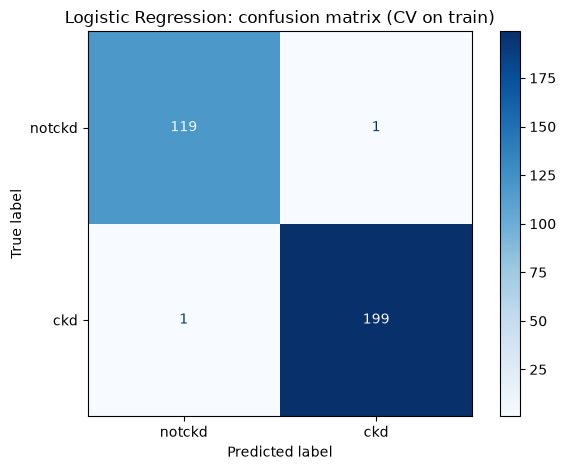

[[119   1]
 [  1 199]]


In [16]:
cm = confusion_matrix(y_train, y_pred_cv)           # [[TN, FP], [FN, TP]]
ConfusionMatrixDisplay(cm, display_labels=["notckd", "ckd"]).plot(cmap="Blues")
plt.title("Logistic Regression: confusion matrix (CV on train)")
plt.tight_layout()
plt.savefig("../reports/figures/cm_logreg_cv.png", dpi=150)
plt.show()
print(cm)

In [17]:

# 1) target column X madhe nahi na, he confirm kara
print("class" in X_train.columns)        # False pahije

# 2) sagle features madhe konta target shi sarvat jast jodlela aahe
# (numeric columns var, simple check)
tmp = X_train[num_cols].copy()           # fakt numeric columns
tmp["target"] = y_train                  # target jodto
print(tmp.corr()["target"].abs().sort_values(ascending=False).head(6))


False
target    1.000000
hemo      0.781314
pcv       0.747561
rbcc      0.738692
sg        0.723542
al        0.626350
Name: target, dtype: float64


In [19]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_validate

# tin models, prattek saathi same preprocessor
models = {
    "LogReg": LogisticRegression(max_iter=1000),
    "RandomForest": RandomForestClassifier(n_estimators=200, random_state=42),   # 200 trees
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
}

# kontya metrics baghaychet (ckd = 1 positive class)
scoring = ["recall", "precision", "f1"]

rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])   # preprocessor + model
    # same cv (aadhi banvlela) vaparla, mhanje fair comparison
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({
        "model": name,
        "recall": res["test_recall"].mean(),
        "recall_std": res["test_recall"].std(),     # folds madhe kiti fark (stability)
        "precision": res["test_precision"].mean(),
        "f1": res["test_f1"].mean(),
    })

results = pd.DataFrame(rows).round(3)
print(results)

          model  recall  recall_std  precision     f1
0        LogReg   0.995        0.01      0.995  0.995
1  RandomForest   1.000        0.00      0.990  0.995
2       XGBoost   0.995        0.01      0.980  0.988


In [20]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import joblib                                  # trained model file madhe save karnyasaathi

# final pipeline: preprocessor + Logistic Regression (RF nivadla tar ithe model badla)
final_model = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000)),
])

final_model.fit(X_train, y_train)              # purna train data var shikto

y_pred = final_model.predict(X_test)           # test set var pahilyandach ani shevtcha prediction

print(classification_report(y_test, y_pred, target_names=["notckd", "ckd"]))

              precision    recall  f1-score   support

      notckd       0.97      1.00      0.98        30
         ckd       1.00      0.98      0.99        50

    accuracy                           0.99        80
   macro avg       0.98      0.99      0.99        80
weighted avg       0.99      0.99      0.99        80



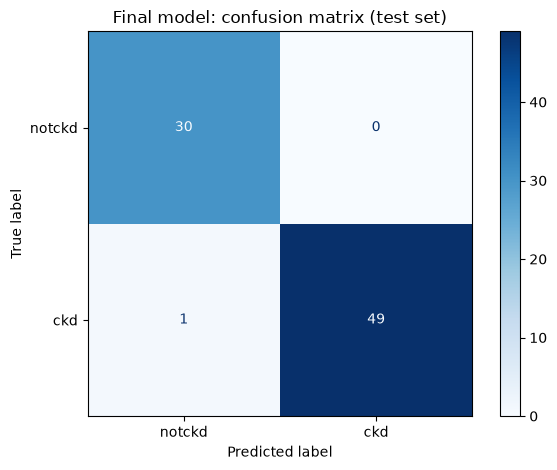

[[30  0]
 [ 1 49]]


In [21]:
cm = confusion_matrix(y_test, y_pred)          # [[TN, FP], [FN, TP]]
ConfusionMatrixDisplay(cm, display_labels=["notckd", "ckd"]).plot(cmap="Blues")
plt.title("Final model: confusion matrix (test set)")
plt.tight_layout()
plt.savefig("../reports/figures/cm_final_test.png", dpi=150)
plt.show()
print(cm)

In [22]:
# preprocessor + model donhi ekach file madhe, app madhe direct vaparta yeil
joblib.dump(final_model, "../models/ckd_pipeline.joblib")

['../models/ckd_pipeline.joblib']

In [23]:
import shap
import numpy as np

# pipeline madhun preprocessor ani model vegle kaadhto
prep = final_model.named_steps["prep"]
lr = final_model.named_steps["model"]

# train ani test donhi preprocess karto (preprocessor aadhich train var fit aahe, mhanun leakage nahi)
Xtr_t = prep.transform(X_train)
Xte_t = prep.transform(X_test)

# preprocessing nantar che columns che naav (age, bp, ..., rbc_normal, ...)
feature_names = prep.get_feature_names_out()

# LinearExplainer: train data background mhanun
explainer = shap.LinearExplainer(lr, Xtr_t)
shap_values = explainer(Xte_t)             # test patients saathi SHAP values
shap_values.feature_names = list(feature_names)

print(shap_values.values.shape)            

Background dataset has 320 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=320 when initializing the masker.


(80, 34)


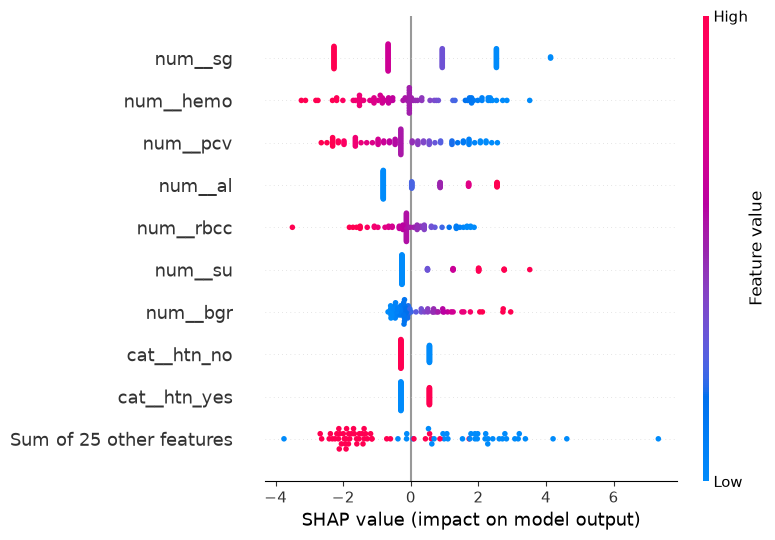

In [24]:
# kontya features sarvat jast mahatvache
shap.plots.beeswarm(shap_values, max_display=10, show=False)
plt.tight_layout()
plt.savefig("../reports/figures/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

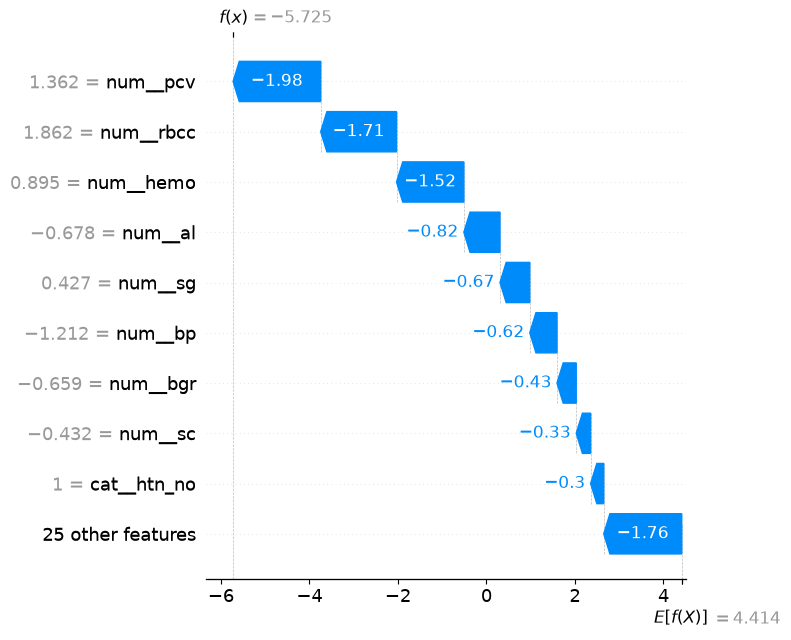

Khara label: 0 | Model cha prediction: 0


In [25]:
# test set madhla pahila patient (index 0)
shap.plots.waterfall(shap_values[0], show=False)
plt.tight_layout()
plt.savefig("../reports/figures/shap_patient0.png", dpi=150, bbox_inches="tight")
plt.show()

print("Khara label:", y_test.iloc[0], "| Model cha prediction:", y_pred[0])